# Parte 1: Importaciones necesarias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image

# Parte 2: Aumento de imágenes
## Carga de datos desde CSV
Vamos a cargar el CSV y luego convertiremos los valores de los píxeles en tensores.

In [4]:
data_df = pd.read_csv('/content/drive/MyDrive/archive/sign_mnist_train.csv')

labels = data_df['label'].values

data_pixels = data_df.drop(columns='label').to_numpy()

images = data_pixels.reshape(-1, 28, 28).astype(np.float32)

print(f"Dimensiones de las imágenes cargadas: {images.shape}")
print(f"Dimensiones de las etiquetas: {labels.shape}")

Dimensiones de las imágenes cargadas: (27455, 28, 28)
Dimensiones de las etiquetas: (27455,)


## Selección de una imagen
Seleccionamos una imagne cualquiera para trabajar con esta imagen.

In [5]:
imagen_seleccionada = images[0]
etiqueta_seleccionada = labels[0]

imagen_pil = Image.fromarray(imagen_seleccionada.astype(np.uint8))

## Aplicación de transformaciones
Procedemos a aplicar 6 transformaicones distintas.

In [6]:
trans_rotacion = transforms.RandomRotation(degrees=(30, 30))

trans_traslacion = transforms.RandomAffine(degrees=0, translate=(0.2, 0.2))

trans_escalado = transforms.Resize((40, 40))

trans_inversion = transforms.RandomInvert(p=1.0)

trans_recorte = transforms.RandomCrop((20, 20))

trans_ruido = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x + torch.randn_like(x) * 0.15), # Añadir ruido gaussiano
    transforms.ToPILImage()
])

img_rotada = trans_rotacion(imagen_pil)
img_trasladada = trans_traslacion(imagen_pil)
img_escalada = trans_escalado(imagen_pil)
img_invertida = trans_inversion(imagen_pil)
img_recortada = trans_recorte(imagen_pil)
img_con_ruido = trans_ruido(imagen_pil)

## Visualización
Mostraremos las imágenes transformadas y las originales en un gráfico.

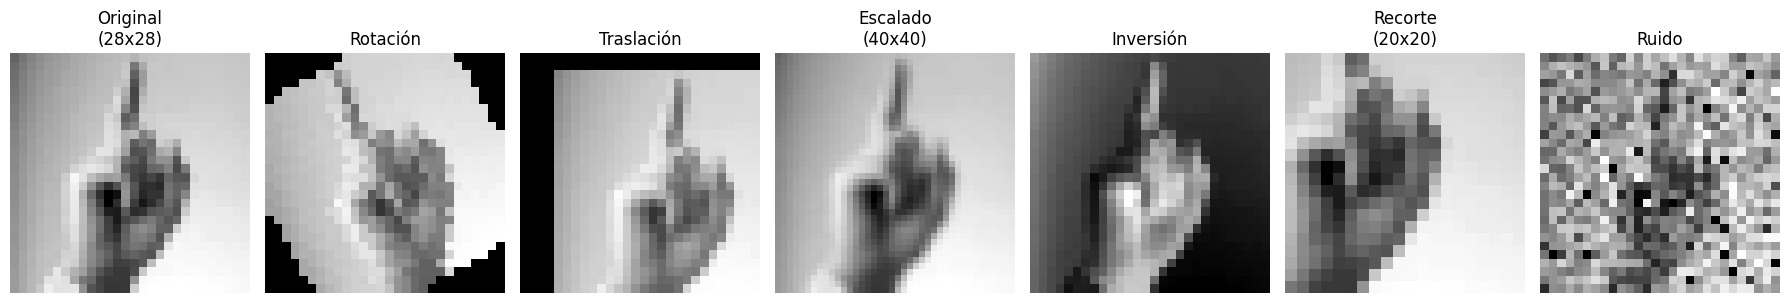

In [7]:
fig, axes = plt.subplots(1, 7, figsize=(18, 4))

imagenes_a_mostrar = [
    (imagen_pil, "Original\n(28x28)"),
    (img_rotada, "Rotación"),
    (img_trasladada, "Traslación"),
    (img_escalada, "Escalado\n(40x40)"),
    (img_invertida, "Inversión"),
    (img_recortada, "Recorte\n(20x20)"),
    (img_con_ruido, "Ruido")
]

for ax, (img, titulo) in zip(axes, imagenes_a_mostrar):
    ax.imshow(img, cmap='gray')
    ax.set_title(titulo)
    ax.axis('off')

plt.tight_layout()
plt.show()

# Parte 3 Exploración de la red convolucional (CNN)
## Carga del conjunto de datos
Convertimos las imágenes en tensores y las normalizamos.

In [8]:
class SignLanguageDataset(Dataset):
    def __init__(self, images_array, labels_array, transform=None):
        self.images = images_array
        self.labels = labels_array
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.fromarray(self.images[idx].astype(np.uint8))
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        return img, label

tensor_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

full_dataset = SignLanguageDataset(images, labels, transform=tensor_transform)

## División del conjunto de datos
Dividimos el conjunto en dos subconjuntos: para entrenamiento y otro para validación.

In [9]:
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

print(f"Total imágenes: {len(full_dataset)}")
print(f"Imágenes de entrenamiento: {len(train_dataset)}")
print(f"Imágenes de validación: {len(val_dataset)}")

Total imágenes: 27455
Imágenes de entrenamiento: 21964
Imágenes de validación: 5491


## Creación del DataLoader
Configuramos el DataLoader para procesar 32 imágenes por lote y establecemos el num_worker=2.

In [10]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

## Experimentación con el modelo CNN
Definimos la red neuronal convolucional y probamos diferentes configuracione.s


In [11]:
class SignCNN(nn.Module):
    def __init__(self, num_classes=26): # 26 letras del abecedario
        super(SignCNN, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1)

        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(-1, 32 * 7 * 7)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SignCNN().to(device)
print(f"Modelo cargado en: {device}")

Modelo cargado en: cuda


## Entrenamiento y evaluación del modelo

In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
print("Iniciando entrenamiento y evaluación...")

for epoch in range(epochs):
    # --- FASE DE ENTRENAMIENTO ---
    model.train()
    train_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # --- FASE DE VALIDACIÓN ---
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total

    print(f"Época [{epoch+1}/{epochs}] | "
          f"Pérdida Entrenamiento: {avg_train_loss:.4f} | "
          f"Pérdida Validación: {avg_val_loss:.4f} | "
          f"Precisión Validación: {val_accuracy:.2f}%")

Iniciando entrenamiento y evaluación...
Época [1/5] | Pérdida Entrenamiento: 0.8541 | Pérdida Validación: 0.0883 | Precisión Validación: 98.14%
Época [2/5] | Pérdida Entrenamiento: 0.0981 | Pérdida Validación: 0.0289 | Precisión Validación: 99.25%
Época [3/5] | Pérdida Entrenamiento: 0.0417 | Pérdida Validación: 0.0036 | Precisión Validación: 100.00%
Época [4/5] | Pérdida Entrenamiento: 0.0281 | Pérdida Validación: 0.0033 | Precisión Validación: 100.00%
Época [5/5] | Pérdida Entrenamiento: 0.0274 | Pérdida Validación: 0.0038 | Precisión Validación: 99.87%
